<a href="https://colab.research.google.com/github/24sahil25-source/BA305-BoardGameGeek-Fall2026/blob/main/notebooks/14_min_ratings_rowan.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 11: how many user ratings must a game have before its average is worth predicting?

A game's `average` is the mean of its users' ratings. With 30 raters it is a noisy number; with 500 it is a stable one. Keeping only games above a minimum number of ratings gives a cleaner target, but fewer games to learn from and a catalogue tilted towards well-known games. This notebook tries five minimum-ratings cut-offs, **30, 50, 100, 200 and 500**, and shows at each how many games are left and how the regression tree, k-NN and the neural network score, then picks a balance.

**The final model keeps all games and does not use a cut-off.** Task 10 (notebook 13) deploys the tree on all of task 1's 21,379 games. This notebook shows what a cut-off would change, and which one would be the balance if one were used.

**`users_rated` is used only to choose rows, never as an input.** It is measured after release (ground rule 4); a check in section 3 asserts that no input column is a post-release one.

Every choice below was made by Rowan John, one decision at a time, before the code was written:

| # | Decision | Choice |
| --- | --- | --- |
| 1 | Models | All three predictive methods: task 1's regression tree and k-NN, and task 2's neural network (`MLPRegressor`), next to `DummyRegressor` |
| 2 | Rows and split | Task 1's rows and split (notebook 05, section 13), unchanged. At each cut-off, the games below it are removed from task 1's training and test games. No game changes sides, and the test games at a higher cut-off are a subset of those at a lower one |
| 3 | Tuning | Re-tuned at every cut-off by 5-fold cross-validation on that cut-off's training games: task 1's grids for the tree (`max_depth` x `min_samples_leaf`) and k-NN (`n_neighbors` x `weights` x `p`) |
| 3b | Network grid | The lab's four architectures, (2,), (5,), (2, 2, 2) and (5, 5, 5), x logistic or ReLU, notebook 06's fix (`tol=1e-8`, `max_iter=2000`), chosen by mean CV RMSE over `random_state` 1 to 3. The chosen network is scored on the test games with seeds 1 to 5, as in notebook 06 |
| 4 | Comparing cut-offs | Each cut-off on its own test games, **and** every cut-off's models on one shared set of reliable games, so the comparison is like-for-like |
| 4b | Shared reliable games | Games with at least **500** ratings, the highest cut-off tried |
| 5 | Mechanic and category columns | The 20 most common mechanics and 15 most common categories are recounted on each cut-off's own training games (ground rule 5) |
| 6 | Picking the cut-off | Cross-validated RMSE on the training games with at least 500 ratings (the test rows are not used to choose). Cut-offs within **0.005 RMSE** of the best, for **all three** models, count as tied (task 1's margin); among tied ones the **lowest** cut-off, which keeps the most games, wins. The test rows then confirm, scored once |
| 6b | If no cut-off ties for all three (added by Rowan John after the first run, when that happened) | Average the three models' like-for-like CV RMSE at each cut-off; cut-offs within **0.005** of the lowest average are tied, and the **lowest** tied cut-off wins |

Ground rules: same loading cell as notebooks 02 to 06; task 1's rows, split, inputs and median imputer; RMSE with MAE and R² next to `DummyRegressor`; no post-release column as an input; every imputer and scaler fitted on training rows only, inside a `Pipeline`; the test rows scored once, at the end.

In [1]:
# --- Rowan John: task 11, minimum-ratings cut-offs (30, 50, 100, 200, 500): games kept and scores at each, and the balance picked ---
# [AI-assisted] Claude Code, 2026-11-11. Every code and markdown cell in this notebook was generated with Claude Code from Rowan John's decisions, notebooks 04 to 06 and the course labs; reviewed and edited by Rowan John.
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from sklearn.base import clone
from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.exceptions import ConvergenceWarning
warnings.simplefilter("ignore", ConvergenceWarning)  # lbfgs warns when it hits max_iter; those fits are counted in section 6
warnings.filterwarnings("ignore", message="A worker stopped")  # joblib's note when it restarts an idle worker process; harmless

## 1. Load the data

In [2]:
# [AI-assisted] Claude Code, 2026-11-11. Same loading cell as notebooks 02 to 06; reviewed and edited by Rowan John.
BASE = "https://raw.githubusercontent.com/24sahil25-source/BA305-BoardGameGeek-Fall2026/main/data/"
games = pd.read_csv(BASE + "bgg_clean.csv")
print(games.shape)

(21631, 24)


In [3]:
# [AI-assisted] Claude Code, 2026-11-11. Figure folder helper as in notebooks 04 and 05, and one fixed colour and marker per model, used in every chart; reviewed and edited by Rowan John.
FIG_DIR = "../figures" if os.path.isdir("../figures") else "."

def save(name):
    plt.savefig(os.path.join(FIG_DIR, name), dpi=200, bbox_inches="tight")

MODELS = ["tree", "k-NN", "neural network"]
STYLE = {"tree": dict(color="#2a78d6", marker="o"), "k-NN": dict(color="#eb6834", marker="s"),
         "neural network": dict(color="#1baf7a", marker="^"), "baseline": dict(color="0.55", marker="x", linestyle="--")}

## 2. Rows and split: task 1's cell, pasted unchanged

Notebook 05's section 13 cell. It keeps 21,379 of the 21,631 games and splits them into 14,964 training and 6,415 test games. Its last lines count the most common mechanics and categories on all training games; here they are recounted at each cut-off instead (decision 5), in section 4.

In [4]:
# [AI-assisted] Claude Code, 2026-11-11. Notebook 05's section 13 cell (rows, split and inputs), pasted unchanged; reviewed and edited by Rowan John.
# ---- paste from here: rows, split, inputs and imputer as settled by task 1 (notebooks/05_imputation_tuning_ansel.ipynb) ----
numeric_cols = ["yearpublished", "minplayers", "maxplayers", "minplaytime", "maxplaytime", "minage", "n_mechanics", "n_categories"]
gaps = games[numeric_cols].isna().sum(axis=1)
data = games[games["yearpublished"].notna() & (gaps < 4)].copy()           # drop no-year games and games missing 4+ of the 8 inputs
data["complete"] = data[numeric_cols].notna().all(axis=1)
tr_c, te_c = train_test_split(data[data["complete"]].reset_index(drop=True), test_size=0.3, random_state=1)    # = notebook 04's split
tr_i, te_i = train_test_split(data[~data["complete"]].reset_index(drop=True), test_size=0.3, random_state=1)
train_df, test_df = pd.concat([tr_c, tr_i], ignore_index=True), pd.concat([te_c, te_i], ignore_index=True)
y_train, y_test = train_df["average"], test_df["average"]

def build_inputs(frame, mechanics, categories):
    X = frame[numeric_cols].copy()
    for col in ["minplayers", "maxplayers", "minplaytime", "maxplaytime"]:
        X[col] = np.log10(X[col])
    mech = frame["boardgamemechanic"].str.get_dummies(sep="|").reindex(columns=mechanics, fill_value=0).add_prefix("mech_")
    cat = frame["boardgamecategory"].str.get_dummies(sep="|").reindex(columns=categories, fill_value=0).add_prefix("cat_")
    flags = pd.DataFrame({"mech_list_missing": frame["boardgamemechanic"].isna().astype(int),
                          "cat_list_missing": frame["boardgamecategory"].isna().astype(int)}, index=frame.index)
    return pd.concat([X, mech, cat, flags], axis=1)

top_mech = train_df["boardgamemechanic"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(20).index
top_cat = train_df["boardgamecategory"].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(15).index
X_train, X_test = build_inputs(train_df, top_mech, top_cat), build_inputs(test_df, top_mech, top_cat)
# Then make the imputer the first step of every model's Pipeline, for example:
#   Pipeline([("impute", <chosen imputer, printed below>), ("scale", StandardScaler()), ("model", KNeighborsRegressor(...))])
# ---- paste to here ----

assert (len(train_df), len(test_df)) == (14964, 6415)
print("task 1's rows:", len(data), "| training games:", len(train_df), "| test games:", len(test_df), "| inputs:", X_train.shape[1])
print("fewest ratings of any game:", int(data["users_rated"].min()))

task 1's rows: 21379 | training games: 14964 | test games: 6415 | inputs: 45
fewest ratings of any game: 30


## 3. How many games each cut-off keeps, and how noisy their averages are

The data has no game with fewer than 30 ratings (`data/README.md`), so **the 30 cut-off keeps every game** and is task 1's setting, the reference the others are compared with.

In [5]:
# [AI-assisted] Claude Code, 2026-11-11. The cut-offs, the shared reliable threshold, and what each cut-off keeps; users_rated is only compared with a number here, to choose rows; reviewed and edited by Rowan John.
CUTOFFS = [30, 50, 100, 200, 500]
RELIABLE = 500          # decision 4b: the shared set of reliable games
MARGIN = 0.005          # decision 6: task 1's tie margin

rows = []
for c in CUTOFFS:
    kept = data[data["users_rated"] >= c]
    rows.append({"cut-off": c, "games kept": len(kept), "share kept (%)": 100 * len(kept) / len(data),
                 "training games": int((train_df["users_rated"] >= c).sum()), "test games": int((test_df["users_rated"] >= c).sum()),
                 "mean rating": kept["average"].mean(), "sd of rating": kept["average"].std(),
                 "median year": kept["yearpublished"].median(), "share with a missing input (%)": 100 * (~kept["complete"]).mean()})
kept_table = pd.DataFrame(rows).set_index("cut-off")
kept_table.round(2)

,games kept,share kept (%),training games,test games,mean rating,sd of rating,median year,share with a missing input (%)
cut-off,,,,,,,,
30,21379,100.00,14964,6415,6.42,0.92,2012.0,15.89
50,17080,79.89,11918,5162,6.48,0.88,2012.0,12.85
100,12090,56.55,8446,3644,6.57,0.83,2012.0,9.18
200,8210,38.40,5746,2464,6.67,0.78,2012.0,6.46
500,4658,21.79,3269,1389,6.83,0.72,2012.0,3.46


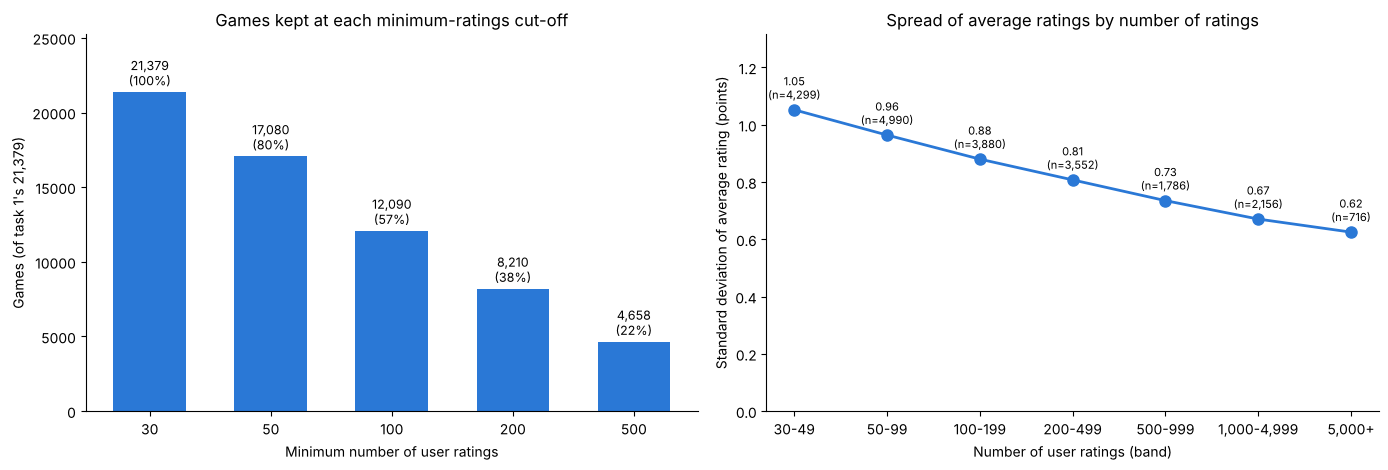

,std,size
users_rated,,
30-49,1.052,4299
50-99,0.964,4990
100-199,0.880,3880
200-499,0.807,3552
500-999,0.735,1786
"1,000-4,999",0.671,2156
"5,000+",0.625,716


In [6]:
# [AI-assisted] Claude Code, 2026-11-11. Two-panel chart: games kept per cut-off, and the spread of averages by number of ratings; reviewed and edited by Rowan John.
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
ax = axes[0]
bars = ax.bar([str(c) for c in CUTOFFS], kept_table["games kept"], color="#2a78d6", width=0.6)
for b, n, s in zip(bars, kept_table["games kept"], kept_table["share kept (%)"]):
    ax.text(b.get_x() + b.get_width() / 2, n + 250, f"{n:,}\n({s:.0f}%)", ha="center", va="bottom", fontsize=9)
ax.set_ylim(0, kept_table["games kept"].max() * 1.18)
ax.set_title("Games kept at each minimum-ratings cut-off")
ax.set_xlabel("Minimum number of user ratings")
ax.set_ylabel("Games (of task 1's 21,379)")
ax.spines[["top", "right"]].set_visible(False)

ax = axes[1]
bands = pd.cut(data["users_rated"], [30, 50, 100, 200, 500, 1000, 5000, np.inf], right=False,
               labels=["30-49", "50-99", "100-199", "200-499", "500-999", "1,000-4,999", "5,000+"])
spread = data.groupby(bands, observed=True)["average"].agg(["std", "size"])
ax.plot(spread.index.astype(str), spread["std"], "o-", color="#2a78d6", linewidth=2, markersize=8)
for x, (sd, n) in enumerate(zip(spread["std"], spread["size"])):
    ax.annotate(f"{sd:.2f}\n(n={n:,})", (x, sd), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=8)
ax.set_ylim(0, spread["std"].max() * 1.25)
ax.set_title("Spread of average ratings by number of ratings")
ax.set_xlabel("Number of user ratings (band)")
ax.set_ylabel("Standard deviation of average rating (points)")
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
save("14_games_kept_and_spread.png")
plt.show()
spread.round(3)

**Takeaway:** each step up costs a large share of the games. 50 ratings keeps 17,080 of 21,379 (80%), 100 keeps 12,090 (57%), 200 keeps 8,210 (38%) and 500 keeps only 4,658 (22%). The games left are also a different catalogue. Their mean rating rises from 6.42 to 6.83 and the spread of ratings falls from 0.92 to 0.72. The share with a missing input falls from 15.9% to 3.5%, so imputation matters less at high cut-offs. The median year stays at 2012 throughout. The right panel shows why a cut-off is tempting: averages from 30 to 49 raters spread with a standard deviation of 1.05, against 0.74 for 500 to 999 raters and 0.63 for 5,000 or more. Few-rater averages are more extreme. Part of that is noise, and part is that obscure games really are different. The data has no per-game spread of individual ratings, so the two cannot be separated here.

## 4. Rows, inputs and folds at each cut-off

For each cut-off, the games below it are removed from task 1's training and test games (decision 2), and the mechanic and category columns are recounted on what is left of the training games (decision 5).

**Folds.** Task 1's `KFold(n_splits=5, shuffle=True, random_state=0)` assigns each of the 14,964 training games to one fold, once. Every cut-off uses that assignment for its own training games. So at the 30 cut-off the folds are exactly notebook 05's, and every cut-off's validation fold *k* holds the same reliable (500+) games. That is what lets section 7 compare cut-offs on identical games.

In [7]:
# [AI-assisted] Claude Code, 2026-11-11. Per-cut-off rows, inputs and folds, with the leakage check; reviewed and edited by Rowan John.
POST_RELEASE = ["rank", "bayes_average", "users_rated", "owned", "trading", "wanting", "wishing"]
folds = KFold(n_splits=5, shuffle=True, random_state=0)
fold_of = np.empty(len(train_df), dtype=int)
for k, (_, va) in enumerate(folds.split(train_df)):
    fold_of[va] = k

def top_entries(frame, column, n):
    return frame[column].str.get_dummies(sep="|").mean().sort_values(ascending=False).head(n).index

def cutoff_data(c):
    tr_mask = (train_df["users_rated"] >= c).values
    te_mask = (test_df["users_rated"] >= c).values
    tr, te = train_df[tr_mask].reset_index(drop=True), test_df[te_mask].reset_index(drop=True)
    shared = test_df[test_df["users_rated"] >= RELIABLE].reset_index(drop=True)
    mech, cat = top_entries(tr, "boardgamemechanic", 20), top_entries(tr, "boardgamecategory", 15)
    d = {"X_train": build_inputs(tr, mech, cat), "y_train": tr["average"].values,
         "X_test": build_inputs(te, mech, cat), "y_test": te["average"].values,
         "X_shared": build_inputs(shared, mech, cat), "y_shared": shared["average"].values,
         "reliable": (tr["users_rated"] >= RELIABLE).values,            # which training games count in section 7's comparison
         "fold": fold_of[tr_mask], "mech": mech, "cat": cat}
    d["splits"] = [(np.where(d["fold"] != k)[0], np.where(d["fold"] == k)[0]) for k in range(5)]
    for X in (d["X_train"], d["X_test"], d["X_shared"]):          # ground rule 4: users_rated chooses rows, it is never an input
        assert not set(POST_RELEASE) & set(X.columns)
    return d

cut = {c: cutoff_data(c) for c in CUTOFFS}
assert cut[30]["X_train"].equals(X_train) and cut[30]["X_test"].equals(X_test)    # the 30 cut-off is task 1's table exactly
check = pd.DataFrame({c: {"training games": len(d["y_train"]), "test games": len(d["y_test"]),
                          "reliable training games": int(d["reliable"].sum()), "shared reliable test games": len(d["y_shared"]),
                          "categories not in task 1's list": ", ".join(sorted(set(d["cat"]) - set(top_cat))) or "-",
                          "mechanics not in task 1's list": ", ".join(sorted(set(d["mech"]) - set(top_mech))) or "-"}
                      for c, d in cut.items()}).T
print("no post-release column is an input at any cut-off; the 30 cut-off reproduces task 1's inputs exactly")
check

no post-release column is an input at any cut-off; the 30 cut-off reproduces task 1's inputs exactly


,training games,test games,reliable training games,shared reliable test games,categories not in task 1's list,mechanics not in task 1's list
30,14964,6415,3269,1389,-,-
50,11918,5162,3269,1389,Deduction,-
100,8446,3644,3269,1389,"Deduction, Medieval",Worker Placement
200,5746,2464,3269,1389,"Deduction, Exploration, Medieval",Worker Placement
500,3269,1389,3269,1389,"Deduction, Exploration, Medieval, Miniatures","Deck, Bag, and Pool Building, Worker Placement"


## 5. Re-tune the tree and k-NN at each cut-off

Task 1's grids and pipelines: median imputer, then the model (the tree), or median imputer, `StandardScaler`, then the model (k-NN). Each grid search uses the cut-off's own training games and the fold assignment from section 4. After the search, the best settings are refitted fold by fold, and each fold's validation games with at least 500 ratings are scored. Those games are identical at every cut-off, and their RMSE is section 7's like-for-like number.

In [8]:
# [AI-assisted] Claude Code, 2026-11-11. Task 1's grids, a grid search per cut-off, an edge check, and the reliable-games RMSE per fold for the best settings; reviewed and edited by Rowan John.
TREE_GRID = {"model__max_depth": [3, 4, 5, 6, 8, 10, 12, 15], "model__min_samples_leaf": [5, 20, 50, 100, 200]}
KNN_GRID = {"model__n_neighbors": [5, 10, 15, 20, 30, 40, 50, 75], "model__weights": ["uniform", "distance"], "model__p": [1, 2]}

def base_pipe(model):
    if model == "tree":
        return Pipeline([("impute", SimpleImputer(strategy="median")), ("model", DecisionTreeRegressor(random_state=0))])
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler()), ("model", KNeighborsRegressor())])

def rmse(y, pred):
    return np.sqrt(mean_squared_error(y, pred))

def reliable_cv(estimator, d):
    # Fit on each cut-off's training folds; score only the validation games with at least RELIABLE ratings.
    out = []
    for tr, va in d["splits"]:
        va_rel = va[d["reliable"][va]]
        m = clone(estimator).fit(d["X_train"].iloc[tr], d["y_train"][tr])
        out.append(rmse(d["y_train"][va_rel], m.predict(d["X_train"].iloc[va_rel])))
    return np.array(out)

searches, tune_rows = {}, []
for c, d in cut.items():
    for model, grid in [("tree", TREE_GRID), ("k-NN", KNN_GRID)]:
        start = time.time()
        s = GridSearchCV(base_pipe(model), grid, cv=d["splits"], scoring="neg_root_mean_squared_error", n_jobs=-1).fit(d["X_train"], d["y_train"])
        searches[(c, model)] = s
        for param, values in grid.items():
            if len(values) > 2 and not isinstance(values[0], str) and s.best_params_[param] in (values[0], values[-1]):
                print(f"  edge: cut-off {c}, {model}: {param} = {s.best_params_[param]} is at the end of {values}")
        rel = reliable_cv(s.best_estimator_, d)
        tune_rows.append({"cut-off": c, "model": model, "settings": {k.replace("model__", ""): v for k, v in s.best_params_.items()},
                          "CV RMSE, own games": -s.best_score_, "sd": s.cv_results_["std_test_score"][s.best_index_],
                          "CV RMSE, 500+ games": rel.mean(), "sd, 500+": rel.std(), "seconds": time.time() - start})
tuned_tk = pd.DataFrame(tune_rows)
tuned_tk.round(4)

,cut-off,model,settings,"CV RMSE, own games",sd,"CV RMSE, 500+ games","sd, 500+",seconds
0,30,tree,"{'max_depth': 12, 'min_samples_leaf': 50}",0.6977,0.0094,0.5898,0.0140,11.0859
1,30,k-NN,"{'n_neighbors': 30, 'p': 1, 'weights': 'distan...",0.7277,0.0077,0.5909,0.0197,45.0507
2,50,tree,"{'max_depth': 12, 'min_samples_leaf': 50}",0.6579,0.0122,0.5706,0.0225,6.7966
3,50,k-NN,"{'n_neighbors': 20, 'p': 1, 'weights': 'distan...",0.6793,0.0092,0.5713,0.0225,29.3632
4,100,tree,"{'max_depth': 10, 'min_samples_leaf': 20}",0.6131,0.0112,0.5470,0.0088,4.3118
5,100,k-NN,"{'n_neighbors': 15, 'p': 1, 'weights': 'distan...",0.6430,0.0104,0.5709,0.0178,16.4605
6,200,tree,"{'max_depth': 10, 'min_samples_leaf': 20}",0.5791,0.0104,0.5360,0.0102,3.2166
7,200,k-NN,"{'n_neighbors': 15, 'p': 1, 'weights': 'distan...",0.6048,0.0108,0.5591,0.0168,8.7430
8,500,tree,"{'max_depth': 8, 'min_samples_leaf': 20}",0.5230,0.0167,0.5230,0.0167,1.7627
9,500,k-NN,"{'n_neighbors': 15, 'p': 1, 'weights': 'distan...",0.5502,0.0247,0.5502,0.0247,4.0652


**Takeaway:** at the 30 cut-off the grid search reproduces task 1 exactly: tree depth 12 with 50 games per leaf (CV RMSE 0.6977), and k-NN with k = 30, distance weights and Manhattan distance (0.7277). As the cut-off rises and the training games shrink, both models settle on simpler settings. The tree goes to depth 10 with 20 per leaf at 100 and 200, then depth 8 at 500. k-NN's k falls from 30 to 20 to 15. Manhattan distance wins at every cut-off. CV RMSE on each cut-off's own games falls steeply (tree 0.698 to 0.523), but most of that is the easier target, so section 7 compares the cut-offs on the same games instead. On the 3,269 reliable training games (the 500+ columns), the tree improves at every step, from 0.590 to 0.523, and k-NN from 0.591 to 0.550.

## 6. Re-tune the neural network at each cut-off

Notebook 06's pipeline: median imputer, `MinMaxScaler`, then `MLPRegressor(solver="lbfgs", tol=1e-8, max_iter=2000)`, with the rating scaled to 0 to 1 by the scale's own limits, 1 and 10. Decision 3b's grid, the lab's four architectures x two activations, is cross-validated with `random_state` 1, 2 and 3 on the same folds. The setting with the lowest CV RMSE averaged over the three seeds is chosen. Each fit also records its RMSE on the fold's reliable games and whether it hit the 2,000-step limit.

In [9]:
# [AI-assisted] Claude Code, 2026-11-11. Network grid over architectures, activations and three seeds at every cut-off, run in parallel; reviewed and edited by Rowan John.
ARCHS = [(2,), (5,), (2, 2, 2), (5, 5, 5)]
ACTS = ["logistic", "relu"]
TUNE_SEEDS, TEST_SEEDS, MAX_ITER = [1, 2, 3], [1, 2, 3, 4, 5], 2000

def to_scaled(r):
    return (np.asarray(r) - 1) / 9

def to_ratings(s):
    return np.asarray(s) * 9 + 1

def nn_pipe(h, act, seed):
    return Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", MinMaxScaler()),
                     ("model", MLPRegressor(hidden_layer_sizes=h, activation=act, solver="lbfgs", tol=1e-8, max_iter=MAX_ITER, random_state=seed))])

def nn_fold(c, h, act, seed, k):
    d = cut[c]
    tr, va = d["splits"][k]
    warnings.simplefilter("ignore", ConvergenceWarning)   # the filter at the top does not reach the parallel worker processes
    m = nn_pipe(h, act, seed).fit(d["X_train"].iloc[tr], to_scaled(d["y_train"][tr]))
    pred = to_ratings(m.predict(d["X_train"].iloc[va]))
    rel = d["reliable"][va]
    return {"cut-off": c, "architecture": str(h), "activation": act, "seed": seed, "fold": k,
            "RMSE own": rmse(d["y_train"][va], pred), "RMSE 500+": rmse(d["y_train"][va][rel], pred[rel]),
            "hit max_iter": m.named_steps["model"].n_iter_ >= MAX_ITER}

start = time.time()
jobs = [(c, h, a, s, k) for c in CUTOFFS for h in ARCHS for a in ACTS for s in TUNE_SEEDS for k in range(5)]
nn_runs = pd.DataFrame(Parallel(n_jobs=-1)(delayed(nn_fold)(*j) for j in jobs))
print(len(nn_runs), "network fits in", round((time.time() - start) / 60, 1), "minutes")

600 network fits in 11.0 minutes


In [10]:
# [AI-assisted] Claude Code, 2026-11-11. Mean over folds, then over seeds, per setting and cut-off; the chosen setting per cut-off; reviewed and edited by Rowan John.
per_seed = nn_runs.groupby(["cut-off", "architecture", "activation", "seed"]).agg(own=("RMSE own", "mean"), rel=("RMSE 500+", "mean"), hits=("hit max_iter", "sum"))
nn_settings = per_seed.groupby(["cut-off", "architecture", "activation"]).agg(
    mean_CV_RMSE=("own", "mean"), sd_over_seeds=("own", "std"), CV_RMSE_500=("rel", "mean"), sd_500=("rel", "std"), max_iter_hits=("hits", "sum"))
nn_best = nn_settings.loc[nn_settings.groupby("cut-off")["mean_CV_RMSE"].idxmin()].reset_index()
nn_best["max_iter_hits"] = nn_best["max_iter_hits"].astype(int).astype(str) + " of 15"
display(nn_settings["mean_CV_RMSE"].unstack("cut-off").round(4))
nn_best.round(4)

cut-off                     30      50      100     200     500
architecture activation                                        
(2, 2, 2)    logistic    0.6973  0.6623  0.6127  0.6465  0.5741
             relu        0.7365  0.7131  0.6866  0.6364  0.5760
(2,)         logistic    0.7089  0.6646  0.8324  0.7000  0.5508
             relu        0.7742  0.7577  0.7120  0.6770  0.6134
(5, 5, 5)    logistic    0.7102  0.6522  0.6070  0.5793  0.5516
             relu        0.7241  0.6837  0.7039  0.6320  0.5849
(5,)         logistic    0.7004  0.6670  0.6535  0.5963  0.5767
             relu        0.7602  0.7077  0.6746  0.6173  0.5540

,cut-off,architecture,activation,mean_CV_RMSE,sd_over_seeds,CV_RMSE_500,sd_500,max_iter_hits
0,30,"(2, 2, 2)",logistic,0.6973,0.0106,0.5655,0.0013,4 of 15
1,50,"(5, 5, 5)",logistic,0.6522,0.0131,0.5451,0.0065,12 of 15
2,100,"(5, 5, 5)",logistic,0.6070,0.0080,0.5286,0.0054,13 of 15
3,200,"(5, 5, 5)",logistic,0.5793,0.0046,0.5256,0.0082,11 of 15
4,500,"(2,)",logistic,0.5508,0.0058,0.5508,0.0058,1 of 15


**Takeaway:** at the 30 cut-off the chosen network is (2, 2, 2) logistic, notebook 06's choice (CV RMSE 0.697 here, against 0.693 there over 5 seeds and a larger grid). At 50, 100 and 200 the choice is (5, 5, 5) logistic, and at 500 it is (2,) logistic. At 500 the top settings are effectively tied: (2,) 0.5508, (5, 5, 5) 0.5516, (5,) ReLU 0.5540. The network is the least stable of the three models. At 100, (2,) logistic averages 0.832 because one seed failed to train. The chosen (5, 5, 5) networks hit the 2,000-step limit in 11 to 13 of their 15 fits, so they were still improving when they stopped, as in notebook 06. On the reliable games, the network is best at 200 (0.5256) and 100 (0.5286), and clearly worse at 500 (0.5508). It is the only model that gets worse when the training games drop from 5,746 to 3,269.

## 7. Pick the cut-off: like-for-like cross-validation on reliable games

Decision 6. For each cut-off and model, the number below is the cross-validated RMSE on the training games with at least 500 ratings, the same games in the same folds at every cut-off. A lower cut-off trains on more, noisier games; a higher one on fewer, cleaner ones. This asks which gives better predictions of ratings that are well measured. The test rows are not used.

In [11]:
# [AI-assisted] Claude Code, 2026-11-11. Like-for-like table, the tie rule and the chosen cut-off; reviewed and edited by Rowan John.
like = pd.concat([tuned_tk.set_index(["cut-off", "model"])["CV RMSE, 500+ games"],
                  nn_best.assign(model="neural network").set_index(["cut-off", "model"])["CV_RMSE_500"]]).unstack("model")[MODELS]
gap = like - like.min()
tied = gap <= MARGIN
all_tied = [c for c in CUTOFFS if tied.loc[c].all()]
mean_like = like.mean(axis=1)                  # decision 6b: the three models' average at each cut-off
mean_tied = [c for c in CUTOFFS if mean_like[c] - mean_like.min() <= MARGIN]
if all_tied:
    CHOSEN, rule = min(all_tied), "decision 6: lowest cut-off tied for all three models"
else:
    CHOSEN, rule = min(mean_tied), f"decision 6b: no cut-off ties for all three; lowest cut-off whose 3-model average is within {MARGIN} of the lowest {mean_tied}"
display(pd.concat({"CV RMSE on 500+ training games": like, "gap to the best": gap}, axis=1).round(4)
        .assign(**{"tied for all three": tied.all(axis=1), "average of 3 models": mean_like, "games kept": kept_table["games kept"]}))
print("cut-offs tied for all three models:", all_tied, "| 3-model average:", mean_like.round(4).to_dict())
print("chosen cut-off:", CHOSEN, "|", rule)

CV RMSE on 500+ training games                        gap to the best  \
model                             tree    k-NN neural network            tree   
cut-off                                                                         
30                              0.5898  0.5909         0.5655          0.0668   
50                              0.5706  0.5713         0.5451          0.0476   
100                             0.5470  0.5709         0.5286          0.0241   
200                             0.5360  0.5591         0.5256          0.0130   
500                             0.5230  0.5502         0.5508          0.0000   

                               tied for all three average of 3 models  \
model      k-NN neural network                                          
cut-off                                                                 
30       0.0406         0.0400              False            0.582068   
50       0.0211         0.0195              False            0.562333   
100      0.0207         0.0030              False            0.548854   
200      0.0089         0.0000              False            0.540227   
500      0.0000         0.0252              False            0.541334   

        games kept  
model               
cut-off             
30           21379  
50           17080  
100          12090  
200           8210  
500           4658

cut-offs tied for all three models: [] | 3-model average: {30: 0.5821, 50: 0.5623, 100: 0.5489, 200: 0.5402, 500: 0.5413}
chosen cut-off: 200 | decision 6b: no cut-off ties for all three; lowest cut-off whose 3-model average is within 0.005 of the lowest [200, 500]


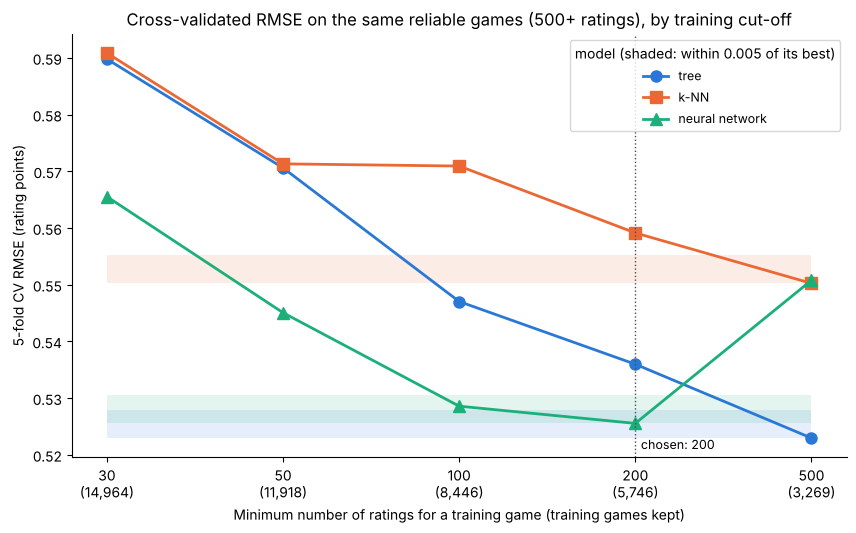

In [12]:
# [AI-assisted] Claude Code, 2026-11-11. Chart of the like-for-like CV RMSE by cut-off, with the tie band for each model; reviewed and edited by Rowan John.
fig, ax = plt.subplots(figsize=(10, 5.5))
x = np.arange(len(CUTOFFS))
for m in MODELS:
    ax.fill_between(x, like[m].min(), like[m].min() + MARGIN, color=STYLE[m]["color"], alpha=0.12, linewidth=0)
    ax.plot(x, like[m].values, linewidth=2, markersize=8, label=m, **STYLE[m])
ax.axvline(CUTOFFS.index(CHOSEN), color="0.3", linestyle=":", linewidth=1)
ax.annotate(f"chosen: {CHOSEN}", (CUTOFFS.index(CHOSEN), ax.get_ylim()[0]), textcoords="offset points", xytext=(4, 6), fontsize=9)
ax.set_xticks(x, [f"{c}\n({n:,})" for c, n in zip(CUTOFFS, kept_table["training games"])])
ax.set_title("Cross-validated RMSE on the same reliable games (500+ ratings), by training cut-off")
ax.set_xlabel("Minimum number of ratings for a training game (training games kept)")
ax.set_ylabel("5-fold CV RMSE (rating points)")
ax.legend(title="model (shaded: within 0.005 of its best)", fontsize=9, loc="upper right")
ax.spines[["top", "right"]].set_visible(False)
save("14_cv_reliable_by_cutoff.png")
plt.show()

**Takeaway:** **the chosen cut-off is 200 ratings, but it is a close call.** No cut-off ties for all three models under decision 6, because the models disagree. The tree and k-NN predict the reliable games better at every step up to 500 (the tree's 0.5230 at 500 is the lowest of all 15 combinations). The network is best at 200 (0.5256) and 0.025 worse at 500. Decision 6b therefore applies. The three-model average is 0.5490 at 100, **0.5402 at 200** and 0.5413 at 500. 200 beats 500 by only 0.001, well inside the network's noise (its spread over seeds on these games is 0.008 at 200), and the tree and k-NN on their own prefer 500. Under decision 6b the two are tied, and the lower cut-off, 200, wins: it keeps 8,210 games, 2.5 times as many as 500. At 200 the tree is 0.013 and k-NN 0.009 behind their own best. Compared with no cut-off (30), every model predicts the reliable games better at 200: the tree by 0.054, the network by 0.040 and k-NN by 0.032. The final model (notebook 13) still keeps all games and uses no cut-off.

## 8. Score the test rows once

Each cut-off's tuned models are fitted on that cut-off's training games: the tree and k-NN by the grid search's refit, the network with seeds 1 to 5 and reported as mean and spread, as in notebook 06. `DummyRegressor` predicts the cut-off's training mean. Two test sets, decision 4:

- **own test games**: task 1's test games with at least that many ratings. This is what a model at that cut-off is for, but the games differ by cut-off, and their ratings are less spread out at higher cut-offs, so the scores are not like-for-like.
- **shared reliable test games**: the same test games with at least 500 ratings, for every cut-off.

In [13]:
# [AI-assisted] Claude Code, 2026-11-11. Fit each cut-off's final models and score both test sets once; reviewed and edited by Rowan John.
def metrics(y, pred):
    return {"games": len(y), "RMSE": rmse(y, pred), "MAE": mean_absolute_error(y, pred), "R2": r2_score(y, pred)}

def nn_final(c, seed):
    d, b = cut[c], nn_best.set_index("cut-off").loc[c]
    warnings.simplefilter("ignore", ConvergenceWarning)
    m = nn_pipe(eval(b["architecture"]), b["activation"], seed).fit(d["X_train"], to_scaled(d["y_train"]))
    return c, seed, to_ratings(m.predict(d["X_test"])), to_ratings(m.predict(d["X_shared"])), m.named_steps["model"].n_iter_

nn_fits = Parallel(n_jobs=-1)(delayed(nn_final)(c, s) for c in CUTOFFS for s in TEST_SEEDS)
rows = []
for c, d in cut.items():
    sets = {"own test games": (d["X_test"], d["y_test"]), "shared reliable test games": (d["X_shared"], d["y_shared"])}
    fitted = {"baseline": DummyRegressor(strategy="mean").fit(d["X_train"], d["y_train"]),
              "tree": searches[(c, "tree")].best_estimator_, "k-NN": searches[(c, "k-NN")].best_estimator_}
    for set_name, (X_, y_) in sets.items():
        for model, est in fitted.items():
            rows.append({"cut-off": c, "test set": set_name, "model": model, **metrics(y_, est.predict(X_)), "sd over seeds": np.nan})
        seed_scores = pd.DataFrame([metrics(y_, own if set_name == "own test games" else shared)
                                    for cc, s, own, shared, _ in nn_fits if cc == c])
        rows.append({"cut-off": c, "test set": set_name, "model": "neural network", **seed_scores.mean().to_dict(),
                     "sd over seeds": seed_scores["RMSE"].std()})
test_scores = pd.DataFrame(rows).set_index(["test set", "cut-off", "model"])
test_scores["games"] = test_scores["games"].astype(int)
print("network final fits that hit max_iter:", sum(n >= MAX_ITER for *_, n in nn_fits), "of", len(nn_fits))
test_scores.round(3)

network final fits that hit max_iter: 16 of 25


games   RMSE    MAE     R2  \
test set                   cut-off model                                        
own test games             30      baseline         6415  0.927  0.728 -0.000   
                                   tree             6415  0.702  0.532  0.427   
                                   k-NN             6415  0.730  0.556  0.379   
                                   neural network   6415  0.698  0.528  0.432   
shared reliable test games 30      baseline         1389  0.825  0.660 -0.304   
                                   tree             1389  0.599  0.476  0.312   
                                   k-NN             1389  0.605  0.478  0.298   
                                   neural network   1389  0.581  0.452  0.354   
own test games             50      baseline         5162  0.892  0.697 -0.000   
                                   tree             5162  0.670  0.506  0.436   
                                   k-NN             5162  0.700  0.532  0.384   
                                   neural network   5162  0.661  0.497  0.451   
shared reliable test games 50      baseline         1389  0.799  0.634 -0.225   
                                   tree             1389  0.586  0.463  0.341   
                                   k-NN             1389  0.590  0.464  0.332   
                                   neural network   1389  0.559  0.434  0.400   
own test games             100     baseline         3644  0.834  0.656 -0.000   
                                   tree             3644  0.613  0.469  0.459   
                                   k-NN             3644  0.651  0.503  0.390   
                                   neural network   3644  0.603  0.461  0.477   
shared reliable test games 100     baseline         1389  0.763  0.599 -0.117   
                                   tree             1389  0.553  0.433  0.413   
                                   k-NN             1389  0.591  0.460  0.330   
                                   neural network   1389  0.546  0.421  0.429   
own test games             200     baseline         2464  0.784  0.615 -0.000   
                                   tree             2464  0.584  0.450  0.445   
                                   k-NN             2464  0.609  0.471  0.398   
                                   neural network   2464  0.573  0.438  0.467   
shared reliable test games 200     baseline         1389  0.737  0.572 -0.041   
                                   tree             1389  0.546  0.428  0.428   
                                   k-NN             1389  0.575  0.448  0.366   
                                   neural network   1389  0.538  0.412  0.445   
own test games             500     baseline         1389  0.722  0.554 -0.000   
                                   tree             1389  0.539  0.410  0.443   
                                   k-NN             1389  0.571  0.431  0.375   
                                   neural network   1389  0.587  0.434  0.339   
shared reliable test games 500     baseline         1389  0.722  0.554 -0.000   
                                   tree             1389  0.539  0.410  0.443   
                                   k-NN             1389  0.571  0.431  0.375   
                                   neural network   1389  0.587  0.434  0.339   

                                                   sd over seeds  
test set                   cut-off model                          
own test games             30      baseline                  NaN  
                                   tree                      NaN  
                                   k-NN                      NaN  
                                   neural network          0.005  
shared reliable test games 30      baseline                  NaN  
                                   tree                      NaN  
                                   k-NN                      NaN  
                                   neural net

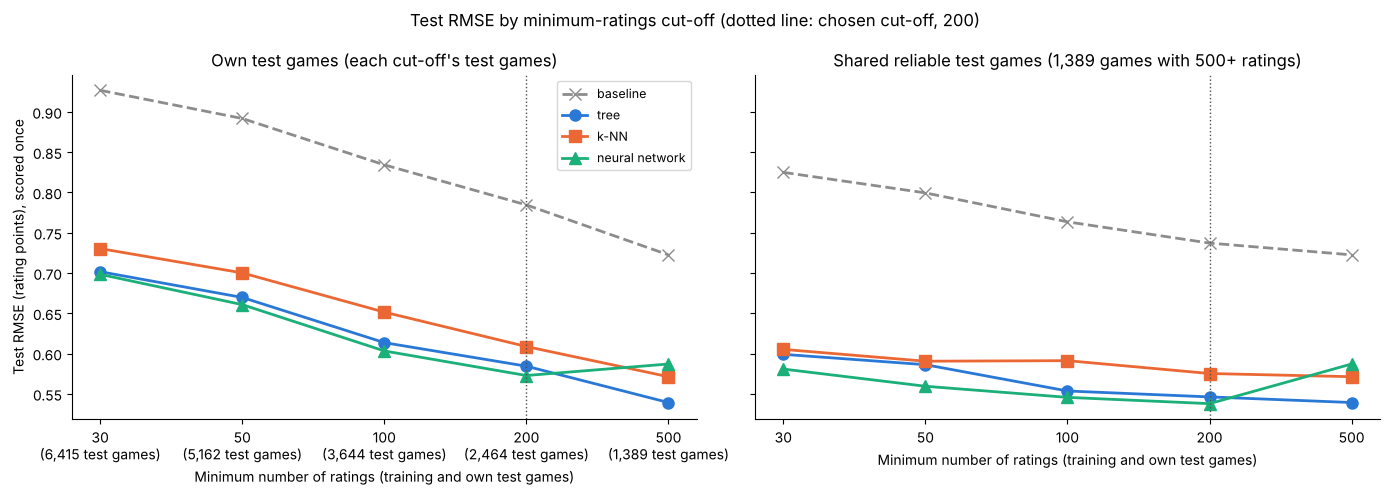

In [14]:
# [AI-assisted] Claude Code, 2026-11-11. Test RMSE by cut-off on both test sets, one panel each, same y-axis; reviewed and edited by Rowan John.
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
x = np.arange(len(CUTOFFS))
for ax, set_name in zip(axes, ["own test games", "shared reliable test games"]):
    t = test_scores.loc[set_name]["RMSE"].unstack("model")
    for m in ["baseline"] + MODELS:
        ax.plot(x, t[m].values, linewidth=2, markersize=8, label=m, **STYLE[m])
    if set_name == "own test games":
        labels = [f"{c}\n({n:,} test games)" for c, n in zip(CUTOFFS, kept_table["test games"])]
    else:
        labels = [f"{c}" for c in CUTOFFS]
        ax.set_title(f"Shared reliable test games ({len(cut[30]['y_shared']):,} games with 500+ ratings)")
    if set_name == "own test games":
        ax.set_title("Own test games (each cut-off's test games)")
    ax.axvline(CUTOFFS.index(CHOSEN), color="0.3", linestyle=":", linewidth=1)
    ax.set_xticks(x, labels)
    ax.set_xlabel("Minimum number of ratings (training and own test games)")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].set_ylabel("Test RMSE (rating points), scored once")
axes[0].legend(fontsize=9)
fig.suptitle(f"Test RMSE by minimum-ratings cut-off (dotted line: chosen cut-off, {CHOSEN})")
plt.tight_layout()
save("14_test_rmse_by_cutoff.png")
plt.show()

In [15]:
# [AI-assisted] Claude Code, 2026-11-11. One summary table: games and test RMSE at every cut-off, with R² on the own test games; reviewed and edited by Rowan John.
own = test_scores.loc["own test games"]
shared = test_scores.loc["shared reliable test games"]
summary = pd.concat({
    "games": kept_table[["training games", "test games", "share kept (%)"]],
    "test RMSE, own games": own["RMSE"].unstack("model")[["baseline"] + MODELS],
    "test R2, own games": own["R2"].unstack("model")[MODELS],
    "test RMSE, 500+ games": shared["RMSE"].unstack("model")[["baseline"] + MODELS],
}, axis=1)
summary.round(3)

games                           test RMSE, own games         \
        training games test games share kept (%)             baseline   tree   
cut-off                                                                        
30               14964       6415        100.000                0.927  0.702   
50               11918       5162         79.891                0.892  0.670   
100               8446       3644         56.551                0.834  0.613   
200               5746       2464         38.402                0.784  0.584   
500               3269       1389         21.788                0.722  0.539   

                              test R2, own games                        \
          k-NN neural network               tree   k-NN neural network   
cut-off                                                                  
30       0.730          0.698              0.427  0.379          0.432   
50       0.700          0.661              0.436  0.384          0.451   
100      0.651          0.603              0.459  0.390          0.477   
200      0.609          0.573              0.445  0.398          0.467   
500      0.571          0.587              0.443  0.375          0.339   

        test RMSE, 500+ games                               
                     baseline   tree   k-NN neural network  
cut-off                                                     
30                      0.825  0.599  0.605          0.581  
50                      0.799  0.586  0.590          0.559  
100                     0.763  0.553  0.591          0.546  
200                     0.737  0.546  0.575          0.538  
500                     0.722  0.539  0.571          0.587

**Takeaway:** **the test rows confirm the choice.** On each cut-off's **own test games**, every RMSE falls as the cut-off rises (tree 0.702 to 0.539). The baseline falls almost as much (0.927 to 0.722), so most of that drop is the easier target, not a better model. R² on the own games moves much less: the tree goes 0.427, 0.436, 0.459, 0.445, 0.443, and the network peaks at 0.477 at 100 and falls to 0.339 at 500. On the **1,389 shared reliable test games**, the like-for-like check, the network trained at 200 scores RMSE 0.538 (± 0.015 over 5 seeds), against 0.581 when trained on every game. The tree goes 0.599 at 30 to 0.546 at 200 to 0.539 at 500, and k-NN 0.605 to 0.575 to 0.571. The network at 200 and the tree at 500 are the two best scores, within 0.001 of each other, as the cross-validation suggested. At 500 the network falls back to 0.587. The baseline has a negative R² on the reliable games at low cut-offs because its training mean (6.42 at 30) is below their mean (6.83).

Two costs of the 200 cut-off are visible here. The network's spread over seeds grows from 0.005 at 30 to 0.015 to 0.018 at 200, because fewer training games make it less stable. And 16 of the 25 final network fits hit the 2,000-step limit.

## 9. The call for the group chat

In [16]:
# [AI-assisted] Claude Code, 2026-11-11. The decision and the code line for the other notebooks, printed for the group-chat post; reviewed and edited by Rowan John.
print("Chosen minimum-ratings cut-off:", CHOSEN, "| games kept:", f"{kept_table.loc[CHOSEN, 'games kept']:,} of {len(data):,}")
print("Tree:", tuned_tk.set_index(["cut-off", "model"]).loc[(CHOSEN, "tree"), "settings"],
      "| k-NN:", tuned_tk.set_index(["cut-off", "model"]).loc[(CHOSEN, "k-NN"), "settings"],
      "| network:", nn_best.set_index("cut-off").loc[CHOSEN, ["architecture", "activation"]].tolist())
print(test_scores.xs(CHOSEN, level="cut-off").round(3).to_string())

Chosen minimum-ratings cut-off: 200 | games kept: 8,210 of 21,379
Tree: {'max_depth': 10, 'min_samples_leaf': 20} | k-NN: {'n_neighbors': 15, 'p': 1, 'weights': 'distance'} | network: ['(5, 5, 5)', 'logistic']
                                           games   RMSE    MAE     R2  sd over seeds
test set                   model                                                    
own test games             baseline         2464  0.784  0.615 -0.000            NaN
                           tree             2464  0.584  0.450  0.445            NaN
                           k-NN             2464  0.609  0.471  0.398            NaN
                           neural network   2464  0.573  0.438  0.467          0.018
shared reliable test games baseline         1389  0.737  0.572 -0.041            NaN
                           tree             1389  0.546  0.428  0.428            NaN
                           k-NN             1389  0.575  0.448  0.366            NaN
                         

### Post for the group chat

> **Task 11 is in: if we used a minimum-ratings cut-off, 200 would be the balance, but it is a close call** (`notebooks/14_min_ratings_rowan.ipynb`). **The final model keeps all games and does not use a cut-off:** task 10 (notebook 13) deploys the tree on all of task 1's 21,379 games, and this notebook shows what a cut-off would change.
>
> **What was done:** task 1's rows and split, with games below each cut-off (30, 50, 100, 200, 500) removed from both halves, so no game changes sides. Tree, k-NN and the network were re-tuned by cross-validation at every cut-off. `users_rated` only chooses rows; it is never an input (asserted in the notebook).
>
> **Games kept:** 30: 21,379 (all) | 50: 17,080 | 100: 12,090 | 200: 8,210 (38%) | 500: 4,658 (22%).
>
> **Why 200:** RMSE on a cut-off's own games always falls as the cut-off rises, but mostly because the target gets easier (the baseline falls too). So every cut-off was also scored on the same reliable games, the ones with 500+ ratings. There, by cross-validation, the network is best at 200 (0.526), while the tree and k-NN keep improving up to 500 and are 0.013 and 0.009 behind their best at 200. Averaged over the three models, 200 (0.540) beats 500 (0.541) by only 0.001, inside the network's noise, and the tree and k-NN on their own prefer 500. The two tie under our rule, and 200 keeps 2.5 times as many games. **Test, 1,389 reliable games:** network trained at 200 0.538 ± 0.015, against 0.581 trained on every game; tree 0.546 (0.599 on every game); k-NN 0.575 (0.605). The tree trained at 500 does slightly better (0.539), on 22% of the games.
>
> **Cost:** 62% of the games are dropped, and the model then predicts the rating of games that will attract 200+ ratings. We can't know that number for a new game before release, so this choice narrows the question to games that will become reasonably well known.
>
> **Code, for reference only; the final model does not use it** (after task 1's cell, before building the inputs; recount the most common mechanics and categories on the new `train_df`):
> ```python
> MIN_RATINGS = 200   # users_rated chooses rows only, never an input
> train_df = train_df[train_df["users_rated"] >= MIN_RATINGS].reset_index(drop=True)
> test_df = test_df[test_df["users_rated"] >= MIN_RATINGS].reset_index(drop=True)
> y_train, y_test = train_df["average"], test_df["average"]
> ```

## 10. What did not work, and notes

- **Decision 6's rule gave no answer.** No cut-off was within 0.005 of the best for all three models, because the network and the other two disagree about 500. Decision 6b, the lowest cut-off whose three-model average is within 0.005 of the lowest, was added after the first run, and the notebook records that. On that average, 200 (0.5402) beats 500 (0.5413) by only 0.001, inside the network's noise (spread over seeds 0.008), and the tree and k-NN on their own prefer 500, so 200 is a close call. Taking the single best model instead would have picked 500 (the tree, 0.5230).
- **Higher cut-offs flatter the scores.** On each cut-off's own games RMSE always falls, and the baseline falls with it (0.927 to 0.722). Reporting only those numbers would have made 500 look best for every model. The shared reliable games are what separate a cleaner target from a better model.
- **The network did not like small data.** At 500 it was worse than at 200 on the reliable games (CV 0.551 against 0.526, test 0.587 against 0.538), and its spread over seeds tripled from 30 to 200. At 100 one seed of (2,) logistic failed to train (mean 0.832).
- **Many network fits ran out of steps.** The chosen (5, 5, 5) logistic hit `max_iter=2000` in 11 to 13 of 15 cross-validation fits, and 16 of the 25 final fits hit it too. Their scores are for networks that had not finished, as in notebook 06.
- **The network grid is smaller than notebook 06's** (decision 3b): four architectures, three tuning seeds, to keep the run under 15 minutes. At the 30 cut-off it still picks notebook 06's (2, 2, 2) logistic.
- **The cut-off changes the question, not just the rows.** A model trained on games with 200+ ratings predicts the rating of games that will become reasonably well known. `users_rated` is not known before release, so this cannot be used to screen a brand-new game without assuming it will attract that many raters. That is a limitation for the report.
- **Caveats on the cross-validation.** The most common mechanics and categories are counted once per cut-off on all its training games, not inside each fold, as in notebooks 04 and 05. The like-for-like numbers use the folds the settings were tuned on, so they are slightly optimistic, equally for every cut-off; the test rows are the unbiased check, and they agree.
- **Results can move slightly on another computer.** Tree and k-NN numbers are exact. The network's `lbfgs` runs can end in slightly different places, so read its numbers as mean ± spread, as in notebook 06.

Reading this notebook:

- One split throughout: task 1's (notebook 05, section 13), with games below each cut-off removed from both halves.
- Every number labelled "CV" uses task 1's fold assignment on training games only. Every number labelled "test" comes from scoring once, at the end.
- Every imputer and scaler sits inside a `Pipeline` and is fitted on training rows only.
- Figures are saved to `figures/` with the prefix `14_`.